In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gzip
import os
import re
from pathlib import Path
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

Libraries imported successfully!
Pandas version: 2.0.3
Matplotlib version: 3.8.0
Seaborn version: 0.12.2


In [27]:
# Define file paths and data directories
BASE_DATA_DIR = r"G:\My Drive\Crick_LMS\projects\a_unstudied_genes"
ALPHAFOLD_STRUCTURES_DIR = os.path.join(BASE_DATA_DIR, "pombe_alphafold_structures", "UP000002485_284812_SCHPO_v6")

# Input data files
GENE_DATA_FILE = os.path.join(BASE_DATA_DIR, "gene_IDs_names_products.tsv")
ALL_UNSTUDIED_FILE = os.path.join(BASE_DATA_DIR, "all_unknown_20260730.tsv")
#PRIORITY_UNSTUDIED_FILE = os.path.join(BASE_DATA_DIR, "priority_unstudied_genes.tsv")

# Output file
OUTPUT_FILE = os.path.join(BASE_DATA_DIR, "pombe_alphafold_structures", "plddt_all_genes_pug_annotations.csv")

print("File paths defined:")
print(f"AlphaFold structures: {ALPHAFOLD_STRUCTURES_DIR}")
print(f"Gene data file: {GENE_DATA_FILE}")
print(f"All unstudied genes: {ALL_UNSTUDIED_FILE}")
#print(f"Priority unstudied genes: {PRIORITY_UNSTUDIED_FILE}")
print(f"Output file: {OUTPUT_FILE}")

File paths defined:
AlphaFold structures: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\UP000002485_284812_SCHPO_v6
Gene data file: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\gene_IDs_names_products.tsv
All unstudied genes: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\all_unknown_20260730.tsv
Output file: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\plddt_all_genes_pug_annotations.csv


In [14]:
# Function to extract pLDDT data from .cif.gz files
def extract_plddt_from_cif(uniprot_id, structures_dir):
    """
    Extract AlphaFold DB ID and pLDDT score from compressed .cif file
    
    Parameters:
    uniprot_id (str): UniProt identifier
    structures_dir (str): Directory containing AlphaFold .cif.gz files
    
    Returns:
    dict: Contains alphafold_id, plddt_score, and error info
    """
    cif_filename = f"AF-{uniprot_id}-F1-model_v6.cif.gz"
    cif_path = os.path.join(structures_dir, cif_filename)
    
    if not os.path.exists(cif_path):
        return {
            'alphafold_id': None,
            'plddt_score': None,
            'error': f'File not found: {cif_filename}'
        }
    
    try:
        alphafold_id = None
        plddt_score = None
        
        with gzip.open(cif_path, 'rt', encoding='utf-8') as f:
            in_qa_metric_section = False
            
            for line in f:
                line = line.strip()
                
                # Extract AlphaFold DB ID from _entry.id
                if line.startswith('_entry.id'):
                    alphafold_id = line.split()[-1] if len(line.split()) > 1 else None
                    #print(f"Extracted AlphaFold ID: {alphafold_id} for UniProt ID: {uniprot_id}")
                # Look for the QA metric section
                if '1 global pLDDT 1 pLDDT' in line:
                    in_qa_metric_section = True
                    continue
                
                # Extract pLDDT score from the line with "1 global pLDDT 1 pLDDT"
                if in_qa_metric_section and '_ma_qa_metric_global.metric_value' in line: #'global' in line and 'pLDDT' in line:
                    parts = line.split()
                    #if len(parts) >= 4 and parts[0].replace('.', '').isdigit():
                    if len(parts) == 2: 
                        try:
                            plddt_score = float(parts[1])
                            break
                        except ValueError:
                            continue
                
                # Stop searching after a reasonable number of lines
                if line.startswith('loop_') and alphafold_id and plddt_score:
                    break
        
        return {
            'alphafold_id': alphafold_id,
            'plddt_score': plddt_score,
            'error': None if (alphafold_id and plddt_score is not None) else 'Could not extract data'
        }
        
    except Exception as e:
        return {
            'alphafold_id': None,
            'plddt_score': None,
            'error': f'Error reading file: {str(e)}'
        }

# print("pLDDT extraction function defined successfully!")

In [9]:
# Load S. pombe gene data
print("Loading S. pombe gene data...")

try:
    # Load main gene data (systematic IDs, names, UniProt IDs)
    genes_df = pd.read_csv(GENE_DATA_FILE, sep='\t')
    
    print(f"Loaded {len(genes_df)} S. pombe genes")
    print(f"Columns: {list(genes_df.columns)}")
    print("\nFirst few rows:")
    print(genes_df.head())
    
    # Check for required columns
    required_columns = ['gene_systematic_id', 'gene_name', 'uniprot_id']
    missing_columns = [col for col in required_columns if col not in genes_df.columns]
    
    if missing_columns:
        print(f"\nWarning: Missing required columns: {missing_columns}")
        print("Available columns:", list(genes_df.columns))
        # Try to find similar column names
        for req_col in missing_columns:
            similar_cols = [col for col in genes_df.columns if req_col.replace('_', '').lower() in col.replace('_', '').lower()]
            if similar_cols:
                print(f"Similar columns for '{req_col}': {similar_cols}")
    
    # Extract unique UniProt IDs
    uniprot_ids = genes_df['uniprot_id'].dropna().unique() if 'uniprot_id' in genes_df.columns else []
    print(f"\nFound {len(uniprot_ids)} unique UniProt IDs")
    if len(uniprot_ids) > 0:
        print("Sample UniProt IDs:", uniprot_ids[:5])
    
except FileNotFoundError:
    print(f"Error: Could not find gene data file: {GENE_DATA_FILE}")
    print("Please check the file path and ensure the file exists.")
    genes_df = None
except Exception as e:
    print(f"Error loading gene data: {str(e)}")
    genes_df = None

Loading S. pombe gene data...
Loaded 12685 S. pombe genes
Columns: ['gene_systematic_id', 'gene_systematic_id_with_prefix', 'gene_name', 'chromosome_id', 'gene_product', 'uniprot_id', 'gene_type', 'synonyms']

First few rows:
  gene_systematic_id gene_systematic_id_with_prefix gene_name chromosome_id  \
0        SPAC1002.01            PomBase:SPAC1002.01     mrx11  chromosome_1   
1        SPAC1002.02            PomBase:SPAC1002.02     pom34  chromosome_1   
2       SPAC1002.03c           PomBase:SPAC1002.03c      gls2  chromosome_1   
3       SPAC1002.04c           PomBase:SPAC1002.04c     taf11  chromosome_1   
4       SPAC1002.05c           PomBase:SPAC1002.05c      jmj2  chromosome_1   

                                        gene_product uniprot_id  \
0  mitochondrial expression network (MIOREX) comp...     Q9US57   
1                                  nucleoporin Pom34     Q9US56   
2                  glucosidase II alpha subunit Gls2     Q9US55   
3   transcription factor TFIID 

In [24]:
# Load unstudied gene classifications
print("Loading unstudied gene classifications...")

try:
    # Load all unstudied genes
    all_unstudied_df = pd.read_csv(ALL_UNSTUDIED_FILE, sep='\t')
    print(f"Loaded {len(all_unstudied_df)} unstudied genes")
    print(f"All unstudied genes columns: {list(all_unstudied_df.columns)}")
    
    # Extract systematic IDs directly using gene_id column
    all_unstudied_ids = set(all_unstudied_df['gene_id'].dropna().tolist())
    priority_unstudied_ids = set(all_unstudied_df[all_unstudied_df['unknown_class'] == 'Priority unstudied']['gene_id'].dropna().tolist())

    print(f"\nIdentified {len(all_unstudied_ids)} unstudied gene systematic IDs")
    print(f"Identified {len(priority_unstudied_ids)} priority unstudied gene systematic IDs")
    
    # Show sample IDs
    print(f"\nSample unstudied gene IDs: {list(all_unstudied_ids)[:5]}")
    print(f"Sample priority unstudied gene IDs: {list(priority_unstudied_ids)[:5]}")
    
except FileNotFoundError as e:
    print(f"Error: Could not find unstudied gene file: {e}")
    all_unstudied_ids = set()
    priority_unstudied_ids = set()
except KeyError as e:
    print(f"Error: Column not found: {e}")
    print("Please check that 'gene_id' column exists in both files")
    all_unstudied_ids = set()
    priority_unstudied_ids = set()

Loading unstudied gene classifications...
Loaded 608 unstudied genes
All unstudied genes columns: ['gene_id', 'unknown_class']

Identified 608 unstudied gene systematic IDs
Identified 138 priority unstudied gene systematic IDs

Sample unstudied gene IDs: ['SPBC1198.03c', 'SPAC25H1.09', 'SPAPB1E7.01c', 'SPAC14C4.04', 'SPBC2A9.11c']
Sample priority unstudied gene IDs: ['SPAC12B10.02c', 'SPCC24B10.18', 'SPBC2A9.11c', 'SPAC683.02c', 'SPAC139.04c']


In [10]:
# Extract pLDDT data from AlphaFold .cif.gz files
if genes_df is not None and 'uniprot_id' in genes_df.columns:
    print("Extracting pLDDT data from AlphaFold .cif.gz files...")
    print(f"Looking in directory: {ALPHAFOLD_STRUCTURES_DIR}")

    # Check if the AlphaFold structures directory exists
    if not os.path.exists(ALPHAFOLD_STRUCTURES_DIR):
        print(f"Warning: AlphaFold structures directory not found: {ALPHAFOLD_STRUCTURES_DIR}")
        print("Please check the path and ensure the directory exists.")
    else:
        # Count available .cif.gz files
        cif_files = [f for f in os.listdir(ALPHAFOLD_STRUCTURES_DIR) if f.endswith('.cif.gz')]
        print(f"Found {len(cif_files)} .cif.gz files in the directory")
        print("Sample files:", cif_files[:5])

    # Filter genes with valid UniProt IDs
    valid_genes = genes_df[genes_df['uniprot_id'].notna()].copy()
    print(f"\nProcessing {len(valid_genes)} genes with valid UniProt IDs...")

    # Extract pLDDT data for each gene
    plddt_results = []

    for idx, row in tqdm(valid_genes.iterrows(), total=len(valid_genes), desc="Extracting pLDDT data"):
        uniprot_id = row['uniprot_id']

        # Extract pLDDT data
        plddt_data = extract_plddt_from_cif(uniprot_id, ALPHAFOLD_STRUCTURES_DIR)

        # Combine gene info with pLDDT data
        result = {
            'gene_systematic_id': row.get('gene_systematic_id', ''),
            'gene_name': row.get('gene_name', ''),
            'uniprot_id': uniprot_id,
            'alphafold_id': plddt_data['alphafold_id'],
            'plddt_score': plddt_data['plddt_score'],
            'extraction_error': plddt_data['error']
        }

        plddt_results.append(result)

    # Create main results dataframe
    results_df = pd.DataFrame(plddt_results)

    print(f"\n=== pLDDT Extraction Results ===\n")
    print(f"Total genes processed: {len(results_df)}")
    print(f"Successful extractions: {results_df['plddt_score'].notna().sum()}")
    print(f"Failed extractions: {results_df['plddt_score'].isna().sum()}")

    if results_df['plddt_score'].notna().sum() > 0:
        valid_plddt = results_df[results_df['plddt_score'].notna()]
        print(f"pLDDT score range: {valid_plddt['plddt_score'].min():.2f} - {valid_plddt['plddt_score'].max():.2f}")
        print(f"Mean pLDDT score: {valid_plddt['plddt_score'].mean():.2f}")

    print("\nSample results:")
    print(results_df.head())

else:
    print("Error: Cannot proceed without valid gene data")
    results_df = None

Extracting pLDDT data from AlphaFold .cif.gz files...
Looking in directory: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\UP000002485_284812_SCHPO_v6
Found 5196 .cif.gz files in the directory
Sample files: ['AF-A0AAN2H660-F1-model_v6.cif.gz', 'AF-A0AAN2H671-F1-model_v6.cif.gz', 'AF-A0AAN2H683-F1-model_v6.cif.gz', 'AF-A0AAN2H698-F1-model_v6.cif.gz', 'AF-A0AAN2H6B6-F1-model_v6.cif.gz']

Processing 5124 genes with valid UniProt IDs...


Extracting pLDDT data: 100%|██████████| 5124/5124 [53:58<00:00,  1.58it/s] 


=== pLDDT Extraction Results ===

Total genes processed: 5124
Successful extractions: 5106
Failed extractions: 18
pLDDT score range: 29.22 - 98.67
Mean pLDDT score: 78.81

Sample results:
  gene_systematic_id gene_name uniprot_id  alphafold_id  plddt_score  \
0        SPAC1002.01     mrx11     Q9US57  AF-Q9US57-F1        72.60   
1        SPAC1002.02     pom34     Q9US56  AF-Q9US56-F1        59.79   
2       SPAC1002.03c      gls2     Q9US55  AF-Q9US55-F1        94.36   
3       SPAC1002.04c     taf11     Q9US54  AF-Q9US54-F1        71.13   
4       SPAC1002.05c      jmj2     Q9US53  AF-Q9US53-F1        79.92   

  extraction_error  
0             None  
1             None  
2             None  
3             None  
4             None  


In [12]:
results_df.to_csv(os.path.join(BASE_DATA_DIR, "pombe_alphafold_structures", "plddt_all_genes.csv"))
results_df

,gene_systematic_id,gene_name,uniprot_id,alphafold_id,plddt_score,extraction_error
0,SPAC1002.01,mrx11,Q9US57,AF-Q9US57-F1,72.60,None
1,SPAC1002.02,pom34,Q9US56,AF-Q9US56-F1,59.79,None
2,SPAC1002.03c,gls2,Q9US55,AF-Q9US55-F1,94.36,None
3,SPAC1002.04c,taf11,Q9US54,AF-Q9US54-F1,71.13,None
4,SPAC1002.05c,jmj2,Q9US53,AF-Q9US53-F1,79.92,None
...,...,...,...,...,...,...
5119,SPMIT.09,atp8,P21536,AF-P21536-F1,95.67,None
5120,SPMIT.10,atp9,P21537,AF-P21537-F1,95.07,None
5121,SPMIT.11,cox2,P21534,AF-P21534-F1,92.86,None
5122,SPMTR.01,mat2-Pc,P10841,None,NaN,File not found: AF-P10841-F1-model_v6.cif.gz


In [25]:
# Add gene classification columns
if results_df is not None:
    print("Adding gene classification columns...")
    # Add boolean columns for gene classifications
    results_df['is_unstudied'] = False
    results_df['is_priority_unstudied'] = False

    # Classify genes based on systematic ID and UniProt ID
    for idx, row in results_df.iterrows():
        systematic_id = row['gene_systematic_id']
        uniprot_id = row['uniprot_id']

        # Check if gene is in unstudied list
        if (systematic_id in all_unstudied_ids):
            results_df.at[idx, 'is_unstudied'] = True

        # Check if gene is in priority unstudied list
        if (systematic_id in priority_unstudied_ids):
            results_df.at[idx, 'is_priority_unstudied'] = True

    # Create category column for easier analysis
    def categorize_gene(row):
        if row['is_priority_unstudied']:
            return 'Priority Unstudied'
        elif row['is_unstudied']:
            return 'Non-Priority Unstudied'
        else:
            return 'Studied'

    results_df['gene_category'] = results_df.apply(categorize_gene, axis=1)

    print("\n=== Gene Classification Summary ===")
    category_counts = results_df['gene_category'].value_counts()
    print(category_counts)

    # Summary of pLDDT scores by category
    valid_results = results_df[results_df['plddt_score'].notna()]
    if len(valid_results) > 0:
        print("\n=== pLDDT Scores by Category ===")
        category_stats = valid_results.groupby('gene_category')['plddt_score'].agg([
            'count', 'mean', 'median', 'std', 'min', 'max'
        ]).round(2)
        print(category_stats)

    print("\nFinal dataframe structure:")
    print(f"Shape: {results_df.shape}")
    print(f"Columns: {list(results_df.columns)}")
    print("\nSample with classifications:")
    print(results_df.head(10))

else:
    print("Error: No results dataframe to classify")

Adding gene classification columns...

=== Gene Classification Summary ===
gene_category
Studied                   4516
Non-Priority Unstudied     470
Priority Unstudied         138
Name: count, dtype: int64

=== pLDDT Scores by Category ===
                        count   mean  median    std    min    max
gene_category                                                    
Non-Priority Unstudied    470  68.20   67.00  18.41  29.22  97.31
Priority Unstudied        138  82.11   85.70  12.98  34.58  97.72
Studied                  4498  79.82   82.12  12.43  30.43  98.67

Final dataframe structure:
Shape: (5124, 9)
Columns: ['gene_systematic_id', 'gene_name', 'uniprot_id', 'alphafold_id', 'plddt_score', 'extraction_error', 'is_unstudied', 'is_priority_unstudied', 'gene_category']

Sample with classifications:
  gene_systematic_id gene_name uniprot_id  alphafold_id  plddt_score  \
0        SPAC1002.01     mrx11     Q9US57  AF-Q9US57-F1        72.60   
1        SPAC1002.02     pom34     Q9US56

Creating barplot comparison for 5106 genes with valid pLDDT scores...

Mean pLDDT scores by category:
Non-Priority Unstudied: 68.20 ± 18.41 (n=470)
Priority Unstudied: 82.11 ± 12.98 (n=138)
Studied: 79.82 ± 12.43 (n=4498)


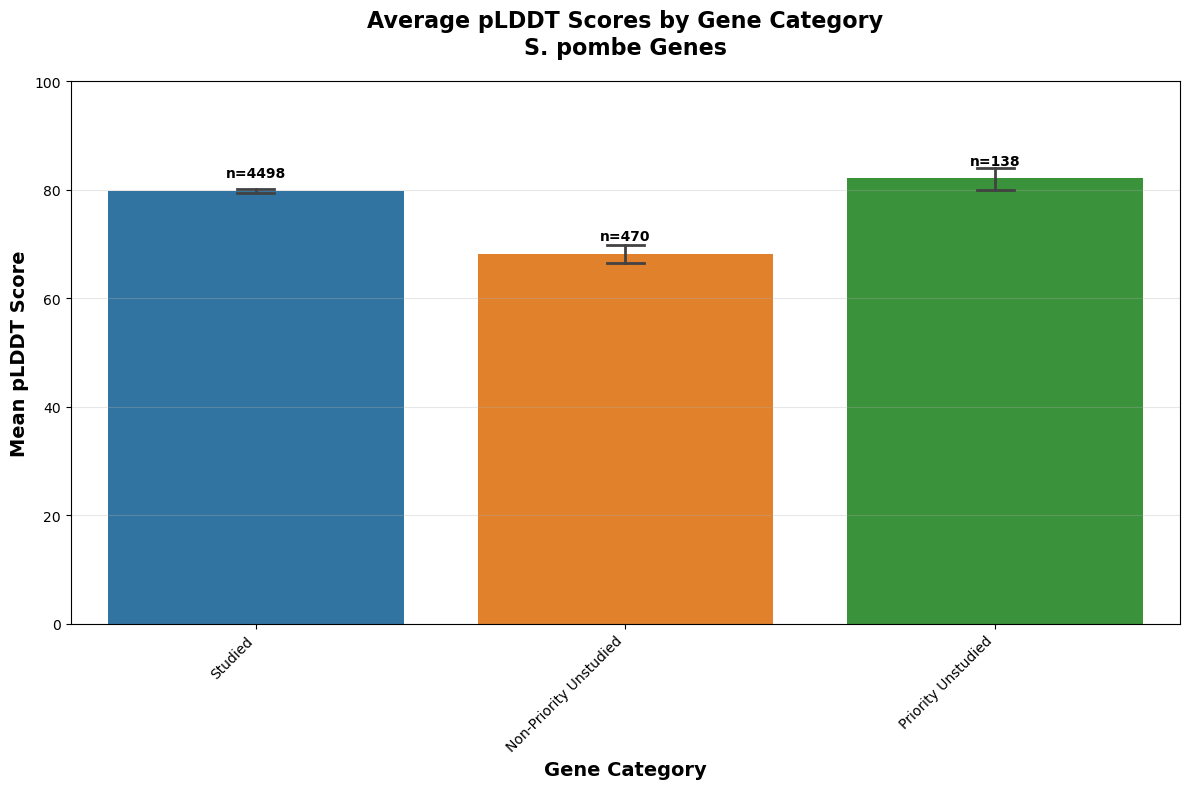


=== Statistical Analysis ===
One-way ANOVA: F-statistic = 171.675, p-value = 6.98e-73
Significant differences detected between gene categories (p < 0.05)


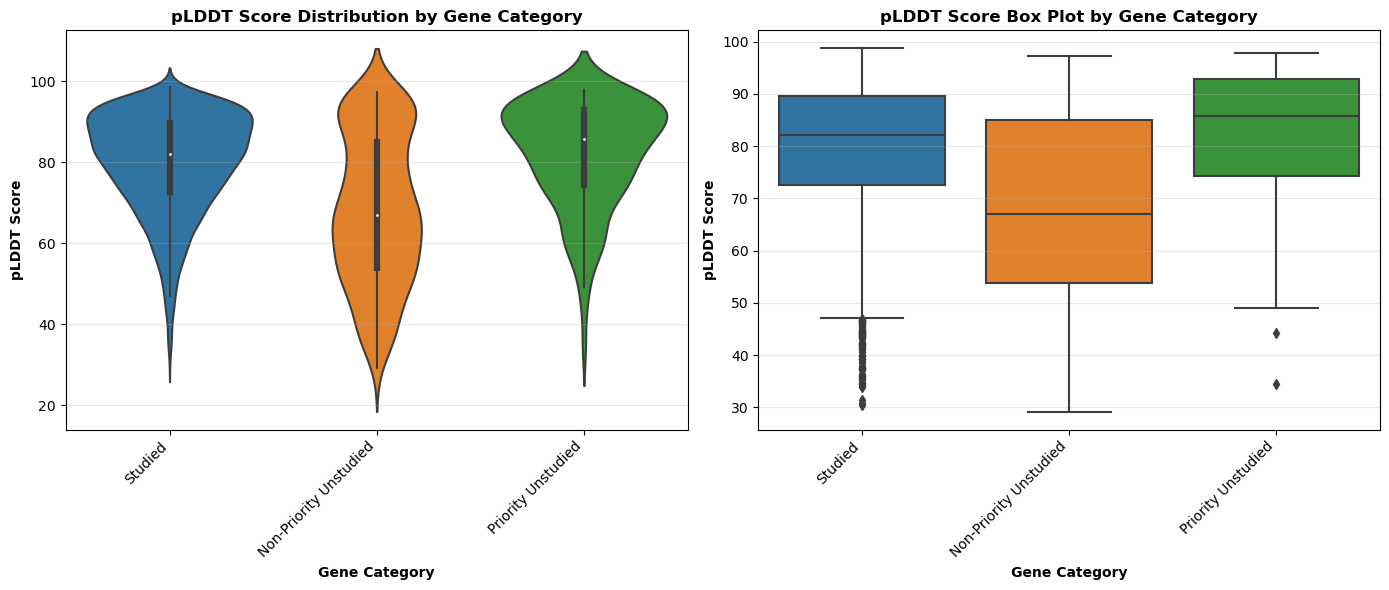

In [26]:
# Create comparison barplot of average pLDDT scores
if results_df is not None:
    # Filter to only genes with valid pLDDT scores
    plot_data = results_df[results_df['plddt_score'].notna()].copy()
    
    if len(plot_data) > 0:
        print(f"Creating barplot comparison for {len(plot_data)} genes with valid pLDDT scores...")
        
        # Calculate mean pLDDT scores by category
        category_means = plot_data.groupby('gene_category')['plddt_score'].agg(['mean', 'count', 'std']).reset_index()
        category_means.columns = ['Category', 'Mean_pLDDT', 'Count', 'StdDev']
        
        print("\nMean pLDDT scores by category:")
        for _, row in category_means.iterrows():
            print(f"{row['Category']}: {row['Mean_pLDDT']:.2f} ± {row['StdDev']:.2f} (n={row['Count']})")
        
        # Create the barplot
        plt.figure(figsize=(12, 8))
        
        # Set color palette
        colors = ['#1f77b4', '#ff7f0e', '#2ca02c']  # Blue, Orange, Green
        
        # Create barplot
        ax = sns.barplot(
            data=plot_data, 
            x='gene_category', 
            y='plddt_score',
            order=['Studied', 'Non-Priority Unstudied', 'Priority Unstudied'],
            palette=colors,
            capsize=0.1,
            errwidth=2
        )
        
        # Customize the plot
        plt.title('Average pLDDT Scores by Gene Category\nS. pombe Genes', fontsize=16, fontweight='bold', pad=20)
        plt.xlabel('Gene Category', fontsize=14, fontweight='bold')
        plt.ylabel('Mean pLDDT Score', fontsize=14, fontweight='bold')
        plt.ylim(0, 100)
        
        # Add count annotations on bars
        for i, category in enumerate(['Studied', 'Non-Priority Unstudied', 'Priority Unstudied']):
            if category in category_means['Category'].values:
                count = category_means[category_means['Category'] == category]['Count'].iloc[0]
                mean_val = category_means[category_means['Category'] == category]['Mean_pLDDT'].iloc[0]
                ax.text(i, mean_val + 2, f'n={count}', ha='center', va='bottom', fontweight='bold')
        
        # Customize appearance
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', alpha=0.3)
        plt.tight_layout()
        
        # Show the plot
        plt.show()
        
        # Additional statistical analysis
        print("\n=== Statistical Analysis ===")
        
        # Perform ANOVA if we have multiple categories
        from scipy.stats import f_oneway
        
        categories = plot_data['gene_category'].unique()
        if len(categories) > 1:
            category_groups = [plot_data[plot_data['gene_category'] == cat]['plddt_score'].values for cat in categories]
            statistic, p_value = f_oneway(*category_groups)
            print(f"One-way ANOVA: F-statistic = {statistic:.3f}, p-value = {p_value:.2e}")
            
            if p_value < 0.05:
                print("Significant differences detected between gene categories (p < 0.05)")
            else:
                print("No significant differences detected between gene categories (p >= 0.05)")
        
        # Create a more detailed comparison plot
        plt.figure(figsize=(14, 6))
        
        # Subplot 1: Violin plot
        plt.subplot(1, 2, 1)
        sns.violinplot(
            data=plot_data, 
            x='gene_category', 
            y='plddt_score',
            order=['Studied', 'Non-Priority Unstudied', 'Priority Unstudied'],
            palette=colors
        )
        plt.title('pLDDT Score Distribution by Gene Category', fontweight='bold')
        plt.xlabel('Gene Category', fontweight='bold')
        plt.ylabel('pLDDT Score', fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', alpha=0.3)
        
        # Subplot 2: Box plot
        plt.subplot(1, 2, 2)
        sns.boxplot(
            data=plot_data, 
            x='gene_category', 
            y='plddt_score',
            order=['Studied', 'Non-Priority Unstudied', 'Priority Unstudied'],
            palette=colors
        )
        plt.title('pLDDT Score Box Plot by Gene Category', fontweight='bold')
        plt.xlabel('Gene Category', fontweight='bold')
        plt.ylabel('pLDDT Score', fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.grid(axis='y', alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
    else:
        print("Error: No valid pLDDT scores available for plotting")
else:
    print("Error: No results dataframe available for plotting")

In [29]:
# Save results to CSV file
if results_df is not None:
    print("Saving results to CSV file...")
    
    # Select final columns for output
    output_columns = [
        'gene_systematic_id',
        'gene_name', 
        'uniprot_id',
        'alphafold_id',
        'plddt_score',
        'is_unstudied',
        'is_priority_unstudied', 
        'gene_category'
    ]
    
    # Create final output dataframe
    final_df = results_df[output_columns].copy()
    
    # Save to CSV
    final_df.to_csv(OUTPUT_FILE, index=False, na_rep='NA')
    
    print(f"Successfully saved {len(final_df)} entries to: {OUTPUT_FILE}")
    
    # Display final summary
    print(f"\n=== Final Output Summary ===")
    print(f"File: {OUTPUT_FILE}")
    print(f"Shape: {final_df.shape}")
    print(f"Columns: {list(final_df.columns)}")
    
    print(f"\n=== Data Completeness ===")
    print(f"Genes with pLDDT scores: {final_df['plddt_score'].notna().sum()} / {len(final_df)} ({100*final_df['plddt_score'].notna().sum()/len(final_df):.1f}%)")
    print(f"Genes with AlphaFold IDs: {final_df['alphafold_id'].notna().sum()} / {len(final_df)}")
    
    print(f"\n=== Category Breakdown ===")
    print(final_df['gene_category'].value_counts())
    
    if final_df['plddt_score'].notna().sum() > 0:
        print(f"\n=== pLDDT Summary by Category ===")
        summary_stats = final_df[final_df['plddt_score'].notna()].groupby('gene_category')['plddt_score'].agg([
            'count', 'mean', 'median', 'std', 'min', 'max'
        ]).round(2)
        print(summary_stats)
    
    print(f"\n✅ Analysis completed successfully!")
    print(f"Results saved to: {OUTPUT_FILE}")
    
else:
    print("Error: No results to save")

Saving results to CSV file...
Successfully saved 5124 entries to: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\plddt_all_genes_pug_annotations.csv

=== Final Output Summary ===
File: G:\My Drive\Crick_LMS\projects\a_unstudied_genes\pombe_alphafold_structures\plddt_all_genes_pug_annotations.csv
Shape: (5124, 8)
Columns: ['gene_systematic_id', 'gene_name', 'uniprot_id', 'alphafold_id', 'plddt_score', 'is_unstudied', 'is_priority_unstudied', 'gene_category']

=== Data Completeness ===
Genes with pLDDT scores: 5106 / 5124 (99.6%)
Genes with AlphaFold IDs: 5106 / 5124

=== Category Breakdown ===
gene_category
Studied                   4516
Non-Priority Unstudied     470
Priority Unstudied         138
Name: count, dtype: int64

=== pLDDT Summary by Category ===
                        count   mean  median    std    min    max
gene_category                                                    
Non-Priority Unstudied    470  68.20   67.00  18.41  29.22  97.31
Prior

# pLDDT Analysis: All S. pombe Genes vs Priority Unstudied Genes (PUGs)

This notebook extracts pLDDT scores from AlphaFold .cif files for all S. pombe genes and compares:
- All S. pombe genes
- Priority unstudied genes (PUGs)
- Non-priority unstudied genes

## Workflow:
1. Load S. pombe gene data (systematic IDs, names, UniProt IDs)
2. Extract pLDDT scores from local AlphaFold .cif.gz files
3. Classify genes into studied/unstudied/priority categories
4. Compare pLDDT distributions between categories

## Data Sources:
- `gene_IDs_names_products.tsv` - All S. pombe genes
- `all_unstudied_genes.tsv` - Unstudied genes
- `priority_unstudied_genes.tsv` - Priority unstudied genes
- AlphaFold .cif.gz files in `pombe_alphafold_structures/`